<a href="https://colab.research.google.com/github/milou101/AI-Pediatric-Pneumonia-Detector-v9/blob/main/Ttp3_vision_p_ordi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install opencv-python numpy matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import shutil

print("OpenCV version:", cv2.__version__)
print("Libraries imported successfully!")

OpenCV version: 5.0.0
Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

os.makedirs("images", exist_ok=True)
os.makedirs("results", exist_ok=True)

# Move uploaded image files into the images folder.
for filename in uploaded.keys():
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
        destination = os.path.join("images", os.path.basename(filename))
        shutil.move(filename, destination)

print("Uploaded image files:", os.listdir("images"))

Saving image1.jpg to image1.jpg
Saving image2.png to image2.png
Saving image3.png to image3.png
Uploaded image files: ['image2.png', 'image1.jpg', 'image3.png']


Total images: 3


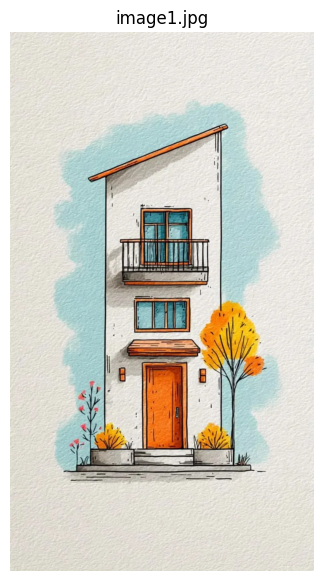

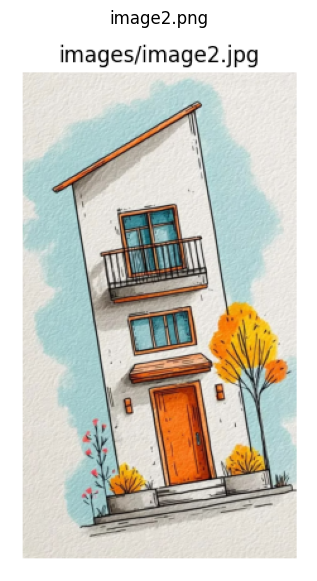

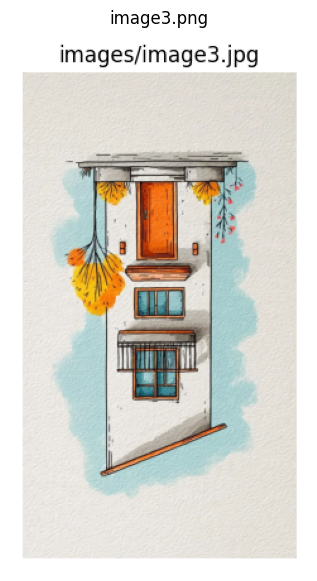

In [ ]:
image_files = sorted(
    glob.glob("images/*.jpg") +
    glob.glob("images/*.jpeg") +
    glob.glob("images/*.png")
)

print("Total images:", len(image_files))
if len(image_files) != 3:
    print("Warning: the TP is intended to use exactly the three supplied images.")

loaded_images = []

for filename in image_files:
    img = cv2.imread(filename)

    if img is None:
        print("Could not read:", filename)
        continue

    loaded_images.append((filename, img))

    plt.figure(figsize=(5, 7))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(os.path.basename(filename))
    plt.axis("off")
    plt.show()

In [ ]:
processed_images = []

for filename, img in loaded_images:
    processed_images.append((filename, img.copy()))
    print(os.path.basename(filename), "->", img.shape)

print("Image loading completed.")

image1.jpg -> (1536, 864, 3)
image2.png -> (427, 236, 3)
image3.png -> (427, 236, 3)
Image loading completed.


In [ ]:
# Number of INNER corners, not the number of squares.
CHECKERBOARD = (9, 6)

criteria = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    30,
    0.001
)

# 3D coordinates of the checkerboard corners.
# The checkerboard is assumed to lie on the Z = 0 plane.
objp = np.zeros(
    (CHECKERBOARD[0] * CHECKERBOARD[1], 3),
    np.float32
)
objp[:, :2] = np.mgrid[
    0:CHECKERBOARD[0],
    0:CHECKERBOARD[1]
].T.reshape(-1, 2)

print("Checkerboard dimensions:", CHECKERBOARD)
print("Internal corners expected per image:", len(objp))
print("First object points:\n", objp[:5])

Checkerboard dimensions: (9, 6)
Internal corners expected per image: 54
First object points:
 [[0. 0. 0.]
 [1. 0. 0.]
 [2. 0. 0.]
 [3. 0. 0.]
 [4. 0. 0.]]


In [ ]:
objpoints = []
imgpoints = []
successful_images = []
gray_images = []

for filename, img in processed_images:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Try the standard detector first.
    flags = (
        cv2.CALIB_CB_ADAPTIVE_THRESH +
        cv2.CALIB_CB_NORMALIZE_IMAGE
    )
    ret, corners = cv2.findChessboardCorners(gray, CHECKERBOARD, flags)

    # Try the more robust SB detector if it is available.
    if not ret and hasattr(cv2, "findChessboardCornersSB"):
        ret, corners = cv2.findChessboardCornersSB(gray, CHECKERBOARD)

    if ret:
        # Refine corner locations for the standard detector.
        if corners is not None and corners.dtype != np.float32:
            corners = corners.astype(np.float32)

        corners2 = cv2.cornerSubPix(
            gray, corners, (11, 11), (-1, -1), criteria
        )

        objpoints.append(objp.copy())
        imgpoints.append(corners2)
        successful_images.append((filename, img.copy()))
        gray_images.append(gray)

        print("SUCCESS:", os.path.basename(filename),
              "-", len(corners2), "corners detected")

        display = img.copy()
        cv2.drawChessboardCorners(display, CHECKERBOARD, corners2, ret)
        plt.figure(figsize=(7, 5))
        plt.imshow(cv2.cvtColor(display, cv2.COLOR_BGR2RGB))
        plt.title("Detected checkerboard corners: " + os.path.basename(filename))
        plt.axis("off")
        plt.show()
    else:
        print("NOT DETECTED:", os.path.basename(filename),
              "- no", CHECKERBOARD, "checkerboard pattern found")

print("\nTotal successful images:", len(successful_images))

NOT DETECTED: image1.jpg - no (9, 6) checkerboard pattern found
NOT DETECTED: image2.png - no (9, 6) checkerboard pattern found
NOT DETECTED: image3.png - no (9, 6) checkerboard pattern found

Total successful images: 0


In [ ]:
calibration_ok = len(objpoints) >= 3

if not calibration_ok:
    print("CALIBRATION SKIPPED.")
    print("Reason: only", len(objpoints), "valid checkerboard image(s) were detected.")
    print("The current house illustrations are not checkerboard calibration targets.")
    print("To perform real calibration, upload at least 3 photos of the same")
    print("9 x 6 internal-corner checkerboard, viewed from different angles.")
else:
    image_size = gray_images[0].shape[::-1]

    if any(gray.shape[::-1] != image_size for gray in gray_images):
        raise ValueError(
            "The detected calibration images have different dimensions. "
            "Resize them consistently before calibration."
        )

    ret, camera_matrix, dist_coeffs, rvecs, tvecs = cv2.calibrateCamera(
        objpoints,
        imgpoints,
        image_size,
        None,
        None
    )

    print("CAMERA CALIBRATION COMPLETED!")
    print("\nCamera Matrix:\n", camera_matrix)
    print("\nDistortion Coefficients:\n", dist_coeffs)
    print("\nRMS calibration error:", ret)

CALIBRATION SKIPPED.
Reason: only 0 valid checkerboard image(s) were detected.
The current house illustrations are not checkerboard calibration targets.
To perform real calibration, upload at least 3 photos of the same
9 x 6 internal-corner checkerboard, viewed from different angles.


In [ ]:
if calibration_ok:
    total_error = 0

    for i in range(len(objpoints)):
        projected_points, _ = cv2.projectPoints(
            objpoints[i],
            rvecs[i],
            tvecs[i],
            camera_matrix,
            dist_coeffs
        )

        error = cv2.norm(
            imgpoints[i],
            projected_points,
            cv2.NORM_L2
        ) / len(projected_points)

        total_error += error

    mean_error = total_error / len(objpoints)
    print("Mean Reprojection Error:", mean_error)
else:
    print("Reprojection error unavailable because calibration was skipped.")

Reprojection error unavailable because calibration was skipped.


In [ ]:
if calibration_ok:
    original = successful_images[0][1].copy()
    h, w = original.shape[:2]

    new_camera_matrix, roi = cv2.getOptimalNewCameraMatrix(
        camera_matrix,
        dist_coeffs,
        (w, h),
        1,
        (w, h)
    )

    undistorted = cv2.undistort(
        original,
        camera_matrix,
        dist_coeffs,
        None,
        new_camera_matrix
    )

    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(undistorted, cv2.COLOR_BGR2RGB))
    plt.title("Undistorted Image")
    plt.axis("off")

    plt.show()
else:
    print("Undistortion skipped: valid camera parameters do not exist.")

Undistortion skipped: valid camera parameters do not exist.


In [ ]:
if calibration_ok:
    cv2.imwrite("results/original_image.jpg", original)
    cv2.imwrite("results/undistorted_image.jpg", undistorted)

    for i, (filename, img) in enumerate(successful_images):
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        ret, corners = cv2.findChessboardCorners(
            gray, CHECKERBOARD,
            cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE
        )

        if ret:
            corners2 = cv2.cornerSubPix(
                gray, corners, (11, 11), (-1, -1), criteria
            )
            output = img.copy()
            cv2.drawChessboardCorners(output, CHECKERBOARD, corners2, ret)
            cv2.imwrite(f"results/detected_corners_{i+1}.jpg", output)

    np.savez(
        "results/calibration_parameters.npz",
        camera_matrix=camera_matrix,
        distortion_coefficients=dist_coeffs,
        rotation_vectors=np.array(rvecs),
        translation_vectors=np.array(tvecs),
        reprojection_error=mean_error
    )

    print("Calibration results saved.")
else:
    print("No calibration files were created because calibration was not possible.")
    print("The input images are still available in the images/ folder.")

No calibration files were created because calibration was not possible.
The input images are still available in the images/ folder.


In [ ]:
if os.path.exists("results") and os.listdir("results"):
    shutil.make_archive(
        "Camera_Calibration_Results",
        "zip",
        "results"
    )
    files.download("Camera_Calibration_Results.zip")
else:
    print("There are no calibration results to download yet.")

There are no calibration results to download yet.
